<a href="https://colab.research.google.com/github/Annette-1/SIMULACION-II/blob/main/Procesos_Derivadas_del_MB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:magenta;"> **Movimiento y Procesos Derivadas del MB** </span>

<span style="color:teal;">**Nombre:** </span> Jerónimo López Annette Michelle

<span style="color:teal;"> **Objetivo:**</span> Modelar matemáticamente fenómenos aleatorios continuos que presentan fluctuaciones impredecibles pero con estructura estadística conocida.

* <span style="color:blue;">**Puente Browviano**</span>

Es el proceso

$$
X_{t}=B_t -tB_1 \quad , \quad 0 ≤t≤1
$$

Obviamente
$$X_0=0 \quad , \quad X_1=0 \quad E(X_t)= cov(X_t,X_s)$$

* <span style="color:blue;">**Movimiento Browviano deriva** </span>
$$
X_t= \mu t + σB_t \quad , \quad t \geq0
$$
 para $$\mu ϵ R \quad y \quad σ>0$$

 $$E(X_t)= cov(X_t,X_s)$$


In [22]:
#Importamos las librerías
import random as r
import numpy as np
import matplotlib.pyplot as plt
from math import erf, sqrt

<span style="color:purple;">**Actividad**</span>

1. Programar el Seudocódigo y graficar una trayectoria para $T=1$ y $L=10$.

2. Graficar en el mismo panel $100$ trayectorias

3. Comentarios y conclusiones.


<span style="color:blue;">**Simulación:** Moivimiento Browviano</span>
Dado $[0,T]$ sea $δt=\frac{T}{L}$, para algún positivo $L$.
Sea $ w_i$ que denote $w(t_i)$ en $t_i=iδt$.

<span style="color:orange;">

*Seudocódigo:*

1. $δt= \frac{T}{L}$
2. $w_0=0$
3. Para $i=0$ a $L-1$:
4.    Calcule un $\xi∼N(0,1)$

5. $w_{i+1}=w_i + \sqrt{δt}\xi_i$
6. Terminar
</span>



> Todos se construyen con funciones a partir del Movimiento Browniano estándar `brown(T,n)`.

In [23]:
def brown(T, n):
    """Trayectoria del MB estándar en [0,T] con n pasos (devuelve n+1 puntos, W_0 = 0)."""
    dt = T / n
    w_0 = 0
    lista = [w_0]
    for i in range(n):
        dw = r.gauss(0, 1)
        w_1 = w_0 + np.sqrt(dt) * dw
        lista.append(w_1)
        w_0 = w_1
    return lista

Definimos los tiempos y los números de punto del **Movimiento Browniano**.

In [24]:
def tiempos(T, n):
    return np.linspace(0, T, n + 1)

**1.** Una trayectoria para $T=1$ y $L=10$.

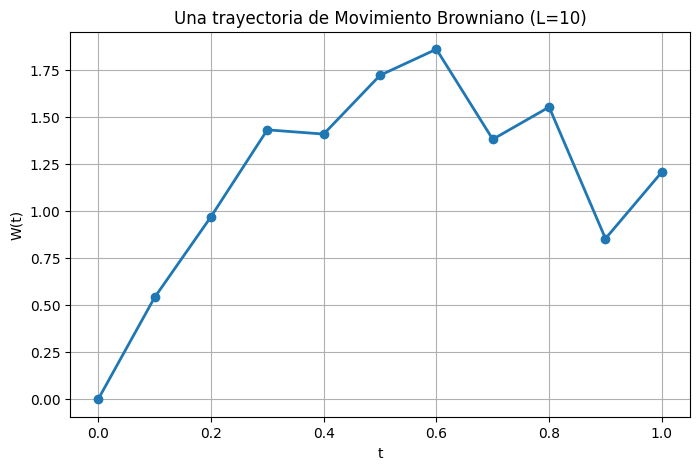

In [25]:
T, L = 1, 10 #Ejemplo de como usar
M = brown(T, L)
plt.figure(figsize=(8, 5))
plt.plot(tiempos(T, L), M, 'o-', lw=2)
plt.title("Una trayectoria de Movimiento Browniano (L=10)")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.grid(True)
plt.show()

Ahora, grafiquemos en el mismo panel $100$ trayectorias simuladas junto con $f(t)=\sqrt {t}$

**Note**: Que las trayectorias inician en $0$.

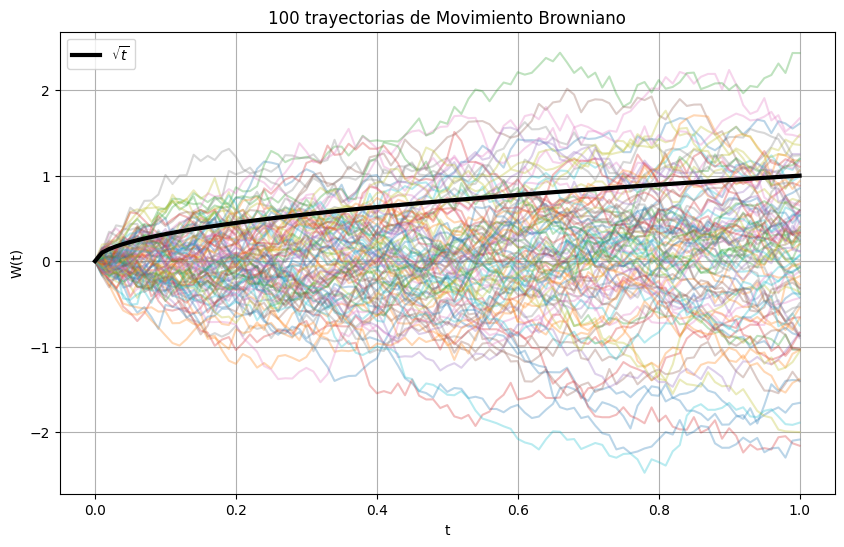

In [26]:
T, L, N = 1, 100, 100
t = tiempos(T, L)
plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, brown(T, L), alpha=0.3)
plt.plot(t, np.sqrt(t), 'k', lw=3, label=r'$\sqrt{t}$')
plt.title("100 trayectorias de Movimiento Browniano")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.legend(); plt.grid(True)
plt.show()

## <span style="color:teal;">**Refinamiento de una trayectoria**</span>

Dada una trayectoria con $n$ pasos de tamaño $\Delta=T/n$, se inserta un punto en el medio de cada intervalo:

$$W_{mid}=\frac{W_{t_i}+W_{t_{i+1}}}{2}+\frac{1}{2}\sqrt{\Delta}\;Z,\qquad Z\sim N(0,1)$$

Así la trayectoria conserva sus puntos originales y pasa a tener $2n$ pasos (de tamaño $\Delta/2$).

In [27]:
def ref(lista, T):
    """Refina una trayectoria del MB en [0,T]: inserta un punto medio en cada intervalo."""
    n = len(lista) - 1            # número de pasos
    dt = np.sqrt(T / n)           # raíz del tamaño de paso actual
    nueva = []
    for i in range(n):
        dw = r.gauss(0, 1)
        w_i = 1/2 * (lista[i] + lista[i+1]) + 1/2 * dw * dt
        nueva.append(lista[i])
        nueva.append(w_i)
    nueva.append(lista[-1])
    return nueva

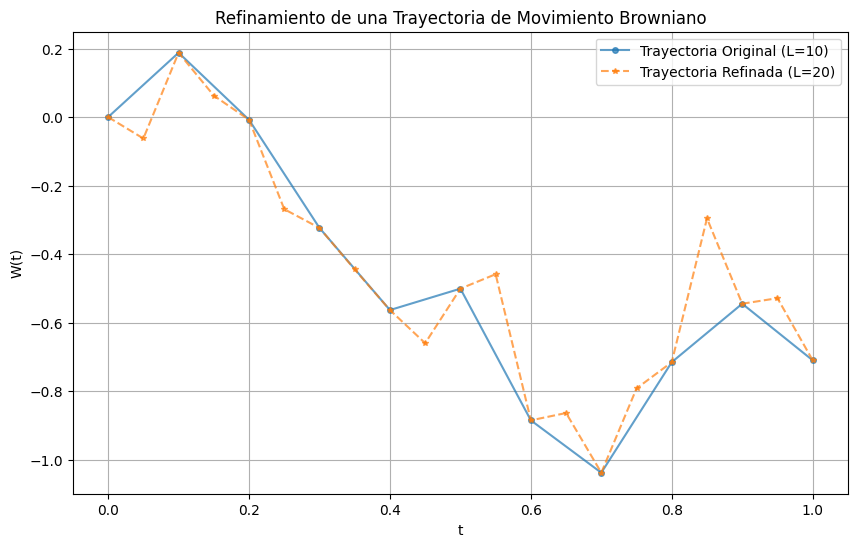

In [28]:
T = 1
L = 10
W_orig = brown(T, L)              # trayectoria original con L=10 pasos
W_ref = ref(W_orig, T)            # trayectoria refinada con 2L=20 pasos

plt.figure(figsize=(10, 6))
plt.plot(tiempos(T, L), W_orig, 'o-', ms=4, alpha=0.7, label=f"Trayectoria Original (L={L})")
plt.plot(tiempos(T, 2*L), W_ref, '*--', ms=4, alpha=0.7, label=f"Trayectoria Refinada (L={2*L})")
plt.title("Refinamiento de una Trayectoria de Movimiento Browniano")
plt.xlabel("t"); plt.ylabel("W(t)"); plt.legend(); plt.grid(True)
plt.show()

Agregamos el Puente Browviano definido como:

$$
X_{t}=B_t -tB_1 \quad , \quad 0 ≤t≤1
$$

Obviamente
$$X_0=0 \quad , \quad X_1=0 \quad E(X_t)= cov(X_t,X_s)$$

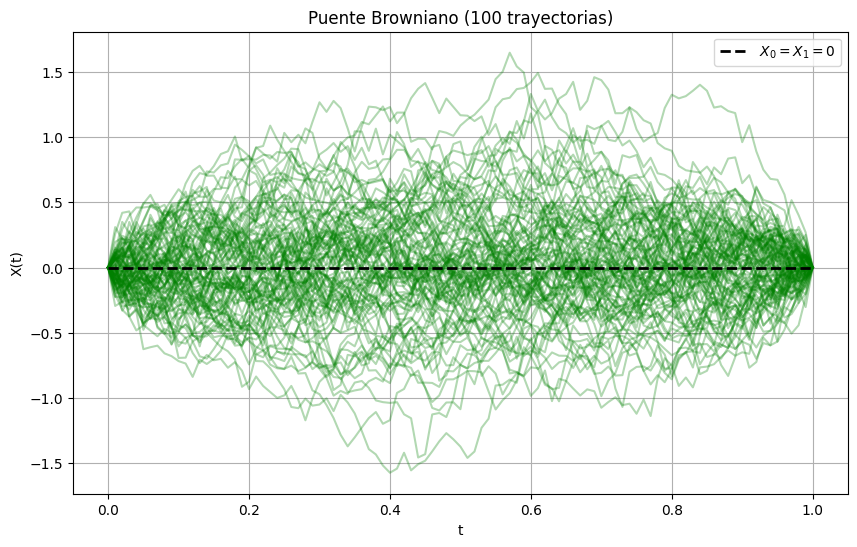

In [29]:
def puente(T, n):
    """Puente Browniano X_t = B_t - (t/T) B_T  (para T=1 es B_t - t B_1)."""
    B = np.array(brown(T, n))
    t = tiempos(T, n)
    return B - (t / T) * B[-1]

T, L, N = 1, 100, 100
t = tiempos(T, L)
plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, puente(T, L), alpha=0.3, color='green')
plt.plot(t, np.zeros_like(t), 'k--', lw=2, label='$X_0 = X_1 = 0$')
plt.title("Puente Browniano (100 trayectorias)")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

<span style="color:teal;">**Puente Browniano $X_t = B_t - t·B_1$**</span>

* Siempre comienza en 0 y termina en 0 en $t=1$
* Se obtiene restando a cada trayectoria Browniana el valor final multiplicado por t
* Útil para simular procesos condicionados a valores iniciales y finales


Usando el movimiento Browviano Deriva:
$$
X_t= \mu t + σB_t \quad , \quad t \geq0
$$
 para $$\mu ϵ R \quad y \quad σ>0$$

In [30]:
def deriva(mu, sigma, T, n):
    """MB con deriva X_t = mu*t + sigma*B_t."""
    B = np.array(brown(T, n))
    return mu * tiempos(T, n) + sigma * B

In [31]:
mu_d, sigma_d = 0.5, 1.0
T, L, N = 1, 100, 100
t = tiempos(T, L)
X_drift = np.array([deriva(mu_d, sigma_d, T, L) for _ in range(N)]) #Refinamiento

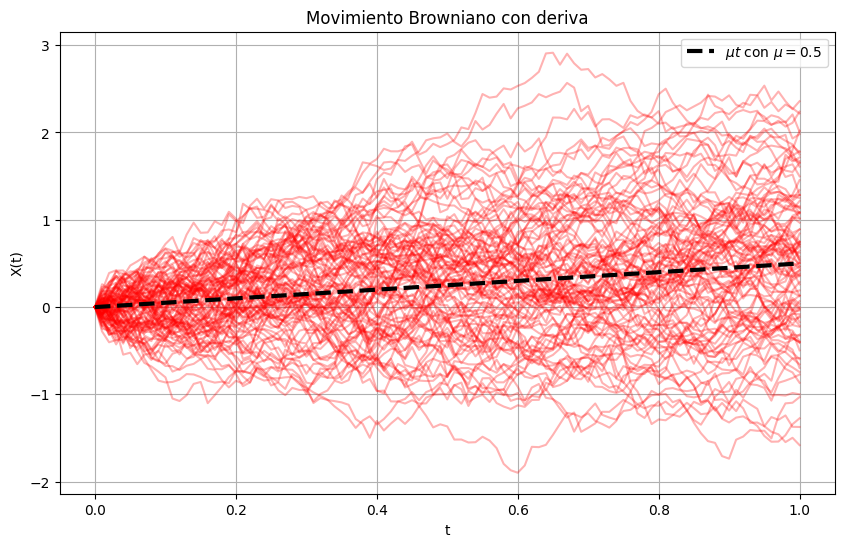

In [32]:
plt.figure(figsize=(10, 6))
for k in range(N):
    plt.plot(t, X_drift[k], alpha=0.3, color='red')
plt.plot(t, mu_d * t, 'k--', lw=3, label=f'$\\mu t$ con $\\mu={mu_d}$')
plt.title("Movimiento Browniano con deriva")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

<span style="color:teal;">**Movimiento Browniano con deriva $X_t = μt + σB_t$**</span>

* Tiene tendencia lineal $μt$ más fluctuaciones aleatorias
* Parámetros: μ (deriva) y σ (volatilidad)
* Media: $E[X_t] = μt$, Varianza: $Var[X_t] = σ²t$

Ahora aplicando movimiento Browviano Geómetrico dada por la expresión:

$$
X_{t}=e ^{\mu t + σB_t} \quad , \quad  t \geq0
$$

In [33]:
# COMPARACIÓN DE ESPERANZAS Y VARIANZAS (teórica vs simulada, en t = T)
print("MOVIMIENTO BROWNIANO CON DERIVA:")
print(f" E[X_t]   teórica  = μt = {mu_d*T:.4f}   simulada = {np.mean(X_drift[:,-1]):.4f}")
print(f" Var[X_t] teórica  = σ²t = {sigma_d**2*T:.4f}   simulada = {np.var(X_drift[:,-1]):.4f}\n")

MOVIMIENTO BROWNIANO CON DERIVA:
 E[X_t]   teórica  = μt = 0.5000   simulada = 0.5194
 Var[X_t] teórica  = σ²t = 1.0000   simulada = 0.7389



Analíticamente calcular la $$E(X_t)= cov(X_t,X_s)$$

**Procesos derivados del Movimiento Browniano**

* Movimiento Browniano estándar

Sea $\{W_t\}_{t\geq 0}$ un movimiento browniano estándar.

Sabemos que

$$
W_t \sim N(0,t).
$$

**Esperanza**

$$
E(W_t)=0.
$$

**Varianza**

Utilizando la definición de varianza,

$$
\operatorname{Var}(W_t)=E(W_t^2)-[E(W_t)]^2.
$$

Como $E(W_t)=0$ y $W_t\sim N(0,t)$,

$$
\operatorname{Var}(W_t)=t.
$$

Por tanto,

$$
\boxed{\operatorname{Var}(W_t)=t.}
$$

* **Covarianza**

Supongamos $s\leq t$. Entonces

$$
W_t=W_s+(W_t-W_s).
$$

Como los incrementos del movimiento browniano son independientes,

$$
\operatorname{Cov}(W_t-W_s,W_s)=0.
$$

Por tanto,
$$
\begin{align*}
\operatorname{Cov}(W_t,W_s)
&=
\operatorname{Cov}(W_s+(W_t-W_s),W_s) \\
&=
\operatorname{Var}(W_s)
+
\operatorname{Cov}(W_t-W_s,W_s) \\
&=
s.
\end{align*}
$$

Luego,

$$
\boxed{\operatorname{Cov}(W_t,W_s)=\min(t,s).}
$$

* **Puente Browniano**

Sea

$$
X_t=W_t-tW_1,
\qquad 0\leq t\leq 1.
$$

* Esperanza

$$
\begin{align*}
E(X_t)
&=
E(W_t-tW_1) \\
&=
E(W_t)-tE(W_1) \\
&=
0.
\end{align*}
$$

Por tanto,

$$
\boxed{E(X_t)=0.}
$$

* Covarianza

Sean

$$
X_t=W_t-tW_1,
\qquad
X_s=W_s-sW_1.
$$

Entonces

$$
\begin{align*}
\operatorname{Cov}(X_t,X_s)
&=
\operatorname{Cov}(W_t-tW_1,W_s-sW_1) \\
&=
\operatorname{Cov}(W_t,W_s)
-s\operatorname{Cov}(W_t,W_1) \\
&\quad
-t\operatorname{Cov}(W_1,W_s)
+ts\operatorname{Var}(W_1).
\end{align*}
$$

Usando

$$
\operatorname{Cov}(W_t,W_s)=\min(t,s),
$$

$$
\operatorname{Cov}(W_t,W_1)=t,
$$

$$
\operatorname{Cov}(W_s,W_1)=s,
$$

y

$$
\operatorname{Var}(W_1)=1,
$$

obtenemos

$$
\begin{align*}
\operatorname{Cov}(X_t,X_s)
&=
\min(t,s)-st-ts+ts \\
&=
\min(t,s)-ts.
\end{align*}
$$
Por tanto,

$$
\boxed{
\operatorname{Cov}(X_t,X_s)
=
\min(t,s)-ts.
}
$$

**Varianza**

Tomando $s=t$,

$$
\operatorname{Var}(X_t)
=
t-t^2.
$$

Por tanto,

$$
\boxed{
\operatorname{Var}(X_t)
=
t(1-t).
}
$$


* **Movimiento Browniano con deriva**

Sea

$$
X_t=\mu t+\sigma W_t,
\qquad \mu\in\mathbb{R},
\quad
\sigma>0.
$$

* Esperanza

$$
\begin{align*}
E(X_t)
&=
E(\mu t+\sigma W_t) \\
&=
\mu t+\sigma E(W_t) \\
&=
\mu t.
\end{align*}
$$

Luego,

$$
\boxed{
E(X_t)=\mu t.
}
$$

* Varianza

$$
\begin{align*}
\operatorname{Var}(X_t)
&=
\operatorname{Var}(\mu t+\sigma W_t) \\
&=
\sigma^2\operatorname{Var}(W_t) \\
&=
\sigma^2 t.
\end{align*}
$$

Por tanto,

$$
\boxed{
\operatorname{Var}(X_t)=\sigma^2 t.
}
$$

* Covarianza

$$
\begin{align*}
\operatorname{Cov}(X_t,X_s)
&=
\operatorname{Cov}(\mu t+\sigma W_t,\mu s+\sigma W_s) \\
&=
\sigma^2\operatorname{Cov}(W_t,W_s).
\end{align*}
$$

Luego,

$$
\boxed{
\operatorname{Cov}(X_t,X_s)
=
\sigma^2\min(t,s).
}
$$


## <span style="color:teal;">**Ejercicio: probabilidad con MB con deriva**</span>

1. Actividad: Encuentre la probabilidad de que el MB con parámetros $\mu=0.6$ y $\sigma^2=0.25$ tome valores entre $1$ y $3$ al tiempo $t=4$.

$$X_t=0.6\,t+0.5\,B_t \quad\Rightarrow\quad X_4=0.6(4)+0.5B_4$$

Como $B_4\sim N(0,4)$:

$$
\begin{align}
X_t &= 0.6t + 0.5B_t \\
\
P(1 < X_4 < 3) &= P(1 < 2.4 + \frac{1}{2}B_4 < 3) \\
&= P(-1.4 < \frac{1}{2}B_4 < 0.6) \\
&= P(-2.8 < B_4 < 1.2) \\
&= \int_{-2.8}^{1.2} \frac{1}{\sqrt{2(4)\pi}} e^{-\frac{x^2}{8}}\\
 dx = 0.6458
\end{align}
$$



In [34]:
# Parámetros del ejemplo
mu, var = 0.6, 0.25
sigma = np.sqrt(var)          # 0.5
t_obj = 4
a, b = 1, 3

In [35]:
# --- Solución exacta: X_4 ~ N(mu*t, sigma^2*t) ---
def Phi(x):                    # función de distribución normal estándar
    return 0.5 * (1 + erf(x / sqrt(2)))

In [36]:
m, s = mu * t_obj, sigma * np.sqrt(t_obj)
p_exacta = Phi((b - m) / s) - Phi((a - m) / s)
print(f"X_4 ~ N({m}, {s**2})")
print(f"P({a} < X_4 < {b}) exacta = {p_exacta:.4f}")

X_4 ~ N(2.4, 1.0)
P(1 < X_4 < 3) exacta = 0.6450


In [37]:
# --- Simulación Monte Carlo usando deriva(mu, sigma, T, n) ---
n_sim, n_pasos = 5000, 100
X4 = np.array([deriva(mu, sigma, t_obj, n_pasos)[-1] for _ in range(n_sim)])
p_sim = np.mean((X4 > a) & (X4 < b))
print(f"P({a} < X_4 < {b}) simulada ({n_sim} trayectorias) = {p_sim:.4f}")

P(1 < X_4 < 3) simulada (5000 trayectorias) = 0.6524


In [38]:
# Gráfica con una sola trayectoria de X_t hasta t=4
tt = tiempos(t_obj, n_pasos)
X = deriva(mu, sigma, t_obj, n_pasos)

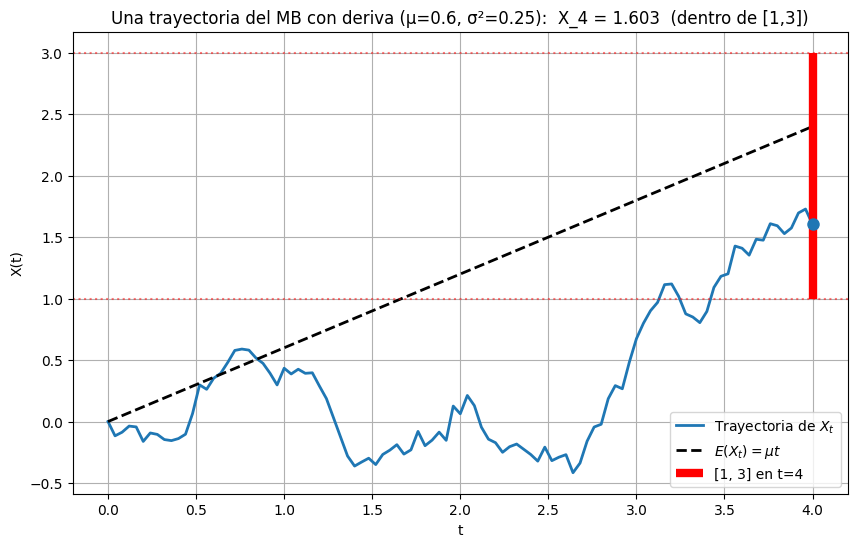

In [39]:
plt.figure(figsize=(10, 6))
plt.plot(tt, X, lw=2, label=r'Trayectoria de $X_t$')
plt.plot(tt, mu * tt, 'k--', lw=2, label=r'$E(X_t)=\mu t$')
plt.vlines(t_obj, a, b, color='red', lw=6, label=f'[{a}, {b}] en t={t_obj}')
plt.axhline(a, color='red', ls=':', alpha=0.5); plt.axhline(b, color='red', ls=':', alpha=0.5)
plt.plot(t_obj, X[-1], 'o', color='C0', ms=8)
dentro = a < X[-1] < b
plt.title(f"Una trayectoria del MB con deriva (μ={mu}, σ²={var}):  X_4 = {X[-1]:.3f}  ({'dentro' if dentro else 'fuera'} de [{a},{b}])")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

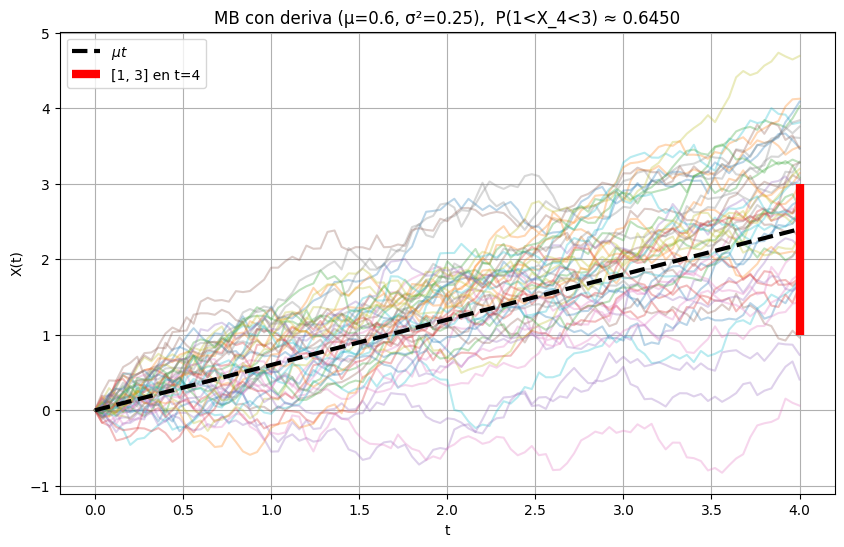

In [40]:
# Gráfica: trayectorias hasta t=4 y banda [1,3] en t=4
plt.figure(figsize=(10, 6))
tt = tiempos(t_obj, n_pasos)
for k in range(50):
    plt.plot(tt, deriva(mu, sigma, t_obj, n_pasos), alpha=0.3)
plt.plot(tt, mu * tt, 'k--', lw=3, label=r'$\mu t$')
plt.vlines(t_obj, a, b, color='red', lw=6, label=f'[{a}, {b}] en t={t_obj}')
plt.title(f"MB con deriva (μ={mu}, σ²={var}),  P({a}<X_4<{b}) ≈ {p_exacta:.4f}")
plt.xlabel("t"); plt.ylabel("X(t)"); plt.legend(); plt.grid(True)
plt.show()

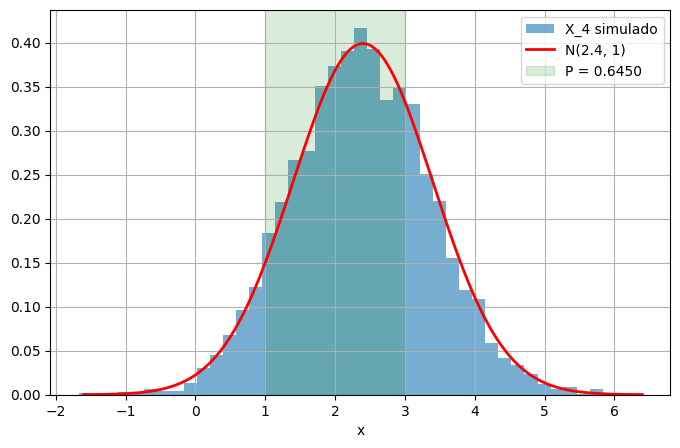

In [41]:
# Histograma de X_4 con la densidad teórica
plt.figure(figsize=(8, 5))
plt.hist(X4, bins=40, density=True, alpha=0.6, label="X_4 simulado")
x = np.linspace(m - 4*s, m + 4*s, 300)
plt.plot(x, np.exp(-(x-m)**2/(2*s**2))/(s*np.sqrt(2*np.pi)), 'r', lw=2, label="N(2.4, 1)")
plt.axvspan(a, b, color='green', alpha=0.15, label=f"P = {p_exacta:.4f}")
plt.xlabel("x"); plt.legend(); plt.grid(True)
plt.show()

## <span style="color:teal;">**Conclusiones:**</span>

El movimiento browniano comienza en $ W(0) = 0 $ y presenta fluctuaciones aleatorias continuas.  
Los incrementos  

$$
W(t + \Delta t) - W(t)
$$

son independientes y siguen una distribución normal  

$$
\mathcal{N}(0, \Delta t).
$$

Aunque cada trayectoria es continua, son extremadamente irregulares; no son diferenciables en ningún punto.  
La dispersión de las trayectorias aumenta con el tiempo. De hecho,

$$
\operatorname{Var}(W(t)) = t,
$$

por lo que la desviación estándar es  

$$
\sqrt{t}.
$$

La curva $ f(t) = \sqrt{t}$ representa precisamente la escala típica de las fluctuaciones del proceso. Se observa que muchas trayectorias permanecen dentro de un rango comparable a $ \pm \sqrt{t}$, aunque algunas pueden alejarse más debido al carácter aleatorio del movimiento.  
Al aumentar el número de trayectorias se aprecia mejor cómo la nube de caminos se ensancha conforme crece $ t$, reflejando el aumento de la varianza.

Además el movimiento browniano es la base matemática de muchos modelos en física (difusión de partículas) y finanzas (modelo de precios de activos).


## <span style="color:teal;">**Conclusión:**</span>

Todos los procesos que revisamos se construyen a partir del movimiento browniano estándar, y las simulaciones coinciden con lo que da la teoría.

* **Movimiento browniano estándar**: las trayectorias parten de $0$ y son continuas pero muy irregulares. Su dispersión crece como $√t$, y por eso se grafican junto con $√t$. Se simula acumulando incrementos independientes $N(0, Δt)$.

* **Refinamiento:** al insertar puntos medios con el ruido correcto se obtiene una trayectoria más fina que conserva todos los puntos originales. Con esto se ve que el MB no es una curva suave: al hacer el paso más pequeño aparecen más oscilaciones.

* **Puente browniano:** $Xₜ = Bₜ − tB₁$ vale $0$ en $t=0$ y en $t=1$.
Su media es $0$ y su varianza es $t(1−t)$, así que es máxima en $t=\frac{1}{2}$ y nula en los extremos.
* **MB con deriva**: $Xₜ = μt + σBₜ$ es una tendencia lineal más ruido. Tiene $E(Xₜ)=μt$ y $Var(Xₜ)=σ²t$, y las trayectorias se abren alrededor de la recta $μt$.

> Valores teóricos y simulados: con 100 trayectorias la media y la varianza simuladas se parecen a las teóricas, pero fluctúan de una corrida a otra. Con más trayectorias el error baja.

Ejemplo de probabilidad: como $X₄ ~ N(2.4, 1)$, se tiene $P(1 < X₄ < 3) = Φ(0.6) − Φ(−1.4) ≈ 0.6450$. Coincide con el valor analítico.